# 02 – Data Preparation and Baseline
Goal: build the clean dataset, split it into train/test, and evaluate two baselines with cross-validation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)

DATA_DIR = Path("../data")
FIG_DIR = Path("../figures"); FIG_DIR.mkdir(exist_ok=True)

## 1. Clean dataset
We repeat the same steps as in notebook 01: we drop `Index`, then recode the target (1 = phishing), and finally remove exact duplicates **before** splitting.

In [2]:
df = pd.read_csv(DATA_DIR / "phishing.csv")
df = df.drop(columns=["Index"])
df["class"] = (df["class"] == -1).astype(int)      # 1 = phishing, 0 = legitimate
df = df.drop_duplicates().reset_index(drop=True)

FEATURES = [c for c in df.columns if c != "class"]
print("Clean dataset:", df.shape)
print(df["class"].value_counts(normalize=True).rename({0: "legitimate", 1: "phishing"}).round(3))

df.to_csv(DATA_DIR / "phishing_clean.csv", index=False)

Clean dataset: (5849, 31)
class
phishing      0.516
legitimate    0.484
Name: proportion, dtype: float64


## 2. Train / test split
We seperate this way : 80 % train / 20 % test, stratified on the target, fixed seed.
We then save the test set and we won't use it again until the final evaluation.

In [3]:
X, y = df[FEATURES], df["class"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print("Train:", X_train.shape, "| phishing share:", round(y_train.mean(), 3))
print("Test: ", X_test.shape,  "| phishing share:", round(y_test.mean(), 3))

pd.concat([X_train, y_train], axis=1).to_csv(DATA_DIR / "train.csv", index=False)
pd.concat([X_test, y_test], axis=1).to_csv(DATA_DIR / "test.csv", index=False)

Train: (4679, 30) | phishing share: 0.516
Test:  (1170, 30) | phishing share: 0.516


## 3. Baselines
- Majority class (DummyClassifier): it always predicts the most frequent class. Minimum level any model must beat.
- Logistic regression: it is a simple linear model, with scikit-learn default settings (max_iter increased so that it converges).

We did no scaling: all features are already on the same −1/0/1 scale. Each model is placed in a Pipeline, so that later our preprocessing steps are always fitted on the training folds only.

In [4]:
models = {
    "Majority class": Pipeline([("clf", DummyClassifier(strategy="most_frequent"))]),
    "Logistic regression": Pipeline([("clf", LogisticRegression(max_iter=1000, random_state=SEED))]),
}

## 4. Cross-validation (5 folds, stratified, on the training set only)

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ["recall", "precision", "f1", "roc_auc", "accuracy"]

rows = {}
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    rows[name] = {m: f"{res['test_' + m].mean():.3f} ± {res['test_' + m].std():.3f}" for m in scoring}

results = pd.DataFrame(rows).T
results

,recall,precision,f1,roc_auc,accuracy
Majority class,1.000 ± 0.000,0.516 ± 0.000,0.681 ± 0.000,0.500 ± 0.000,0.516 ± 0.000
Logistic regression,0.918 ± 0.008,0.929 ± 0.010,0.923 ± 0.003,0.976 ± 0.002,0.921 ± 0.004


**Reading the results.**
- After deduplication, we find that phishing is the majority class, so the majority-class baseline always predicts phishing: its recall is 1.0 but its precision is only ≈ 0.52 and its ROC-AUC is 0.5. This shows why recall alone is not enough: it must be read together with precision, F1 and ROC-AUC.
- Logistic regression is the real reference: every advanced model will have to beat it.

## 5. Confusion matrix of the logistic regression (cross-validated predictions)

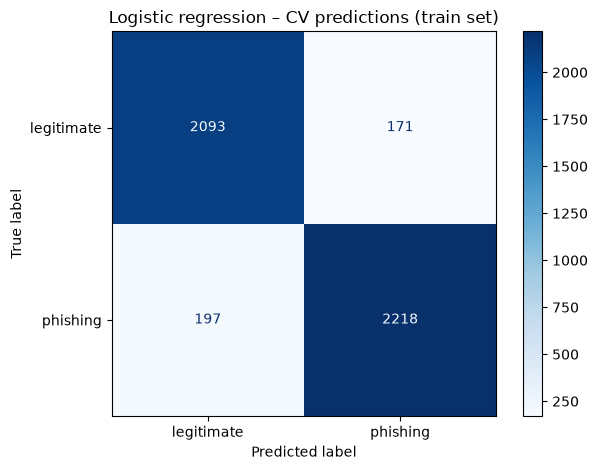

Missed phishing websites (false negatives): 197
False alarms (false positives): 171


In [6]:
y_pred = cross_val_predict(models["Logistic regression"], X_train, y_train, cv=cv)
cm = confusion_matrix(y_train, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["legitimate", "phishing"]).plot(cmap="Blues")
plt.title("Logistic regression – CV predictions (train set)")
plt.tight_layout(); plt.savefig(FIG_DIR / "baseline_confusion_matrix.png", dpi=150); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Missed phishing websites (false negatives): {fn}")
print(f"False alarms (false positives): {fp}")

## 6. Most important features for the logistic regression

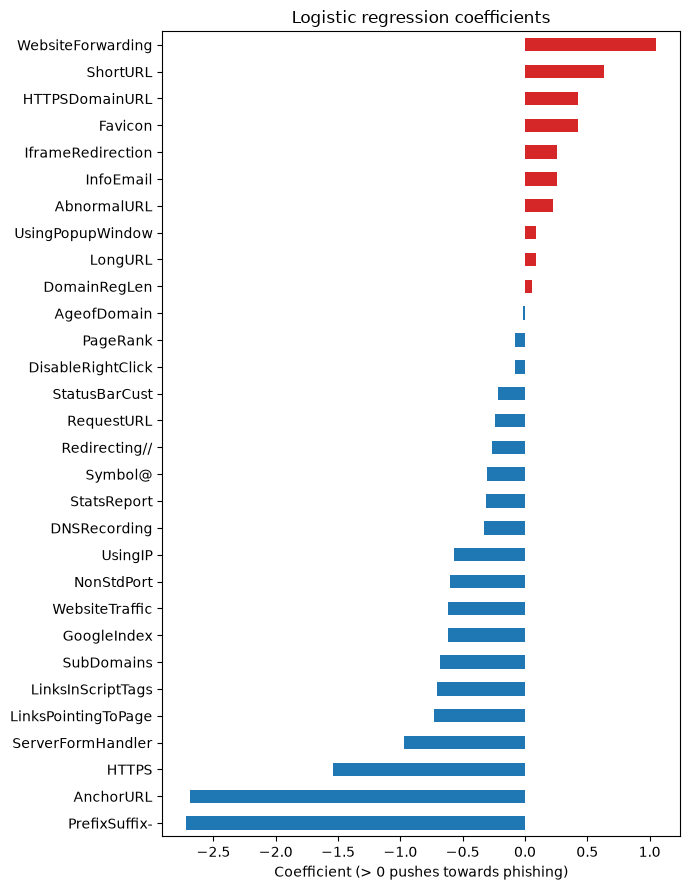

In [7]:
lr = models["Logistic regression"].fit(X_train, y_train)
coefs = pd.Series(lr.named_steps["clf"].coef_[0], index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 9))
coefs.plot.barh(ax=ax, color=np.where(coefs > 0, "tab:red", "tab:blue"))
ax.set_xlabel("Coefficient (> 0 pushes towards phishing)")
ax.set_title("Logistic regression coefficients")
plt.tight_layout(); plt.savefig(FIG_DIR / "baseline_coefficients.png", dpi=150); plt.show()

## Conclusions

The cleaned dataset is saved as phishing_clean.csv, and the train/test split as train.csv and test.csv, so every following notebook uses exactly the same data. The majority-class baseline reaches perfect recall without learning anything, which shows that recall must always be read together with precision and F1. Logistic regression gives the reference scores that the next models (decision tree, Random Forest, Gradient Boosting…) will have to beat. The test set has not been used yet and is kept for the final evaluation.